In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
%pip install -q ultralytics supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.2 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 460.4/460.4 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 54.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from pathlib import Path

import cv2
import torch
import matplotlib.pyplot as plt
import ultralytics
import supervision as sv

WORK_DIR = Path("/kaggle/working/yolo_tracking")
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)
print("Supervision version:", sv.__version__)
print("GPU available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "GPU is not available. Check that the Kaggle GPU session is running."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Project folder:", WORK_DIR)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch version: 2.11.0+cu128
Ultralytics version: 8.4.183
Supervision version: 0.31.0
GPU available: True
GPU: Tesla T4
Project folder: /kaggle/working/yolo_tracking


In [3]:
from supervision.assets import download_assets, VideoAssets

download_assets(VideoAssets.VEHICLES)

VIDEO_PATH = WORK_DIR / VideoAssets.VEHICLES.value

assert VIDEO_PATH.exists(), f"Video was not found: {VIDEO_PATH}"

print("Downloaded video:", VIDEO_PATH)
print("Size in MB:", round(VIDEO_PATH.stat().st_size / (1024 ** 2), 2))

[2026-10-20 08:35:49] [INFO] supervision.assets.downloader - Downloading vehicles.mp4 assets


  0%|          | 0/35345757 [00:00<?, ?it/s]

Downloaded video: /kaggle/working/yolo_tracking/vehicles.mp4
Size in MB: 33.71


Resolution: 3840 × 2160
Source FPS: 25.00
Total frames: 538
Duration: 21.5 seconds


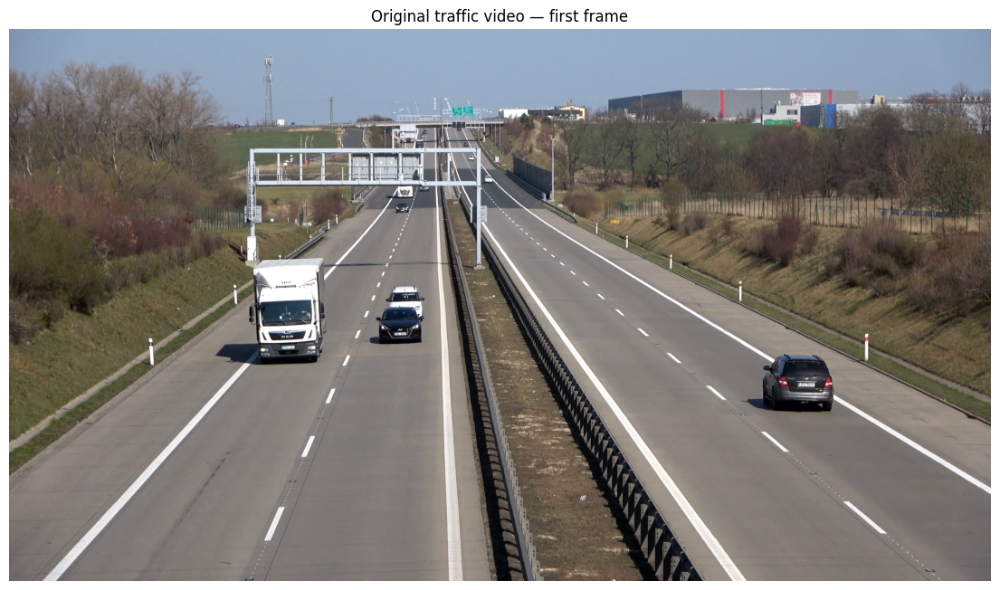

In [4]:
cap = cv2.VideoCapture(str(VIDEO_PATH))

assert cap.isOpened(), "OpenCV could not open the downloaded video."

video_fps = cap.get(cv2.CAP_PROP_FPS)
video_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

success, first_frame = cap.read()
cap.release()

assert success, "Could not read the first frame."

print(f"Resolution: {video_width} × {video_height}")
print(f"Source FPS: {video_fps:.2f}")
print(f"Total frames: {video_frames}")

if video_fps > 0:
    print(f"Duration: {video_frames / video_fps:.1f} seconds")

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
plt.title("Original traffic video — first frame")
plt.axis("off")
plt.show()

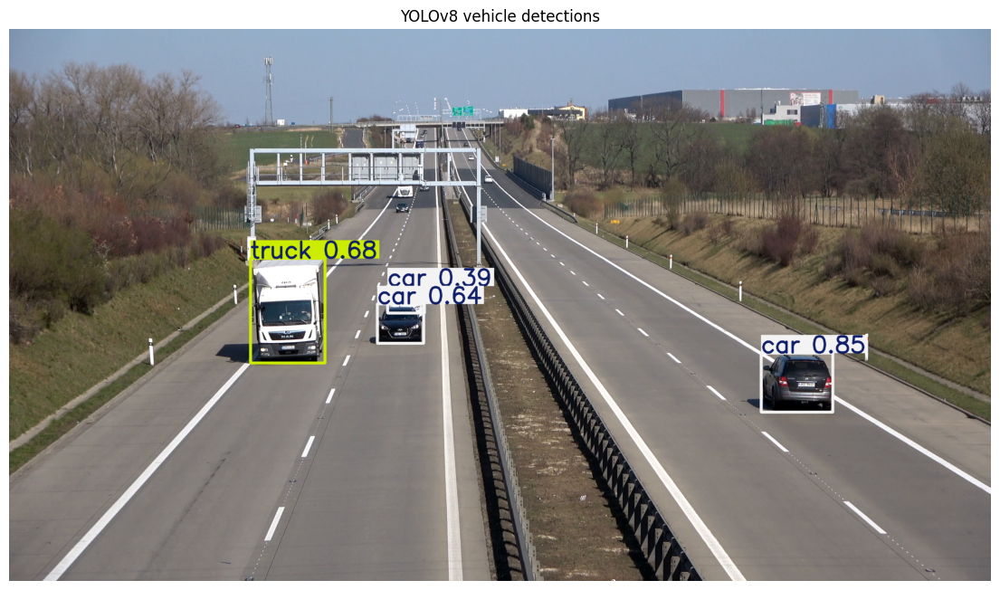

Vehicles detected in this frame: 4
Saved preview: /kaggle/working/yolo_tracking/first_frame_detections.jpg


In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

VEHICLE_CLASSES = [2, 3, 5, 7]

result = model.predict(
    source=first_frame,
    classes=VEHICLE_CLASSES,
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False,
)[0]

annotated_frame = result.plot()

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8 vehicle detections")
plt.axis("off")
plt.show()

print("Vehicles detected in this frame:", len(result.boxes))

preview_path = WORK_DIR / "first_frame_detections.jpg"
cv2.imwrite(str(preview_path), annotated_frame)

print("Saved preview:", preview_path)

In [6]:
for box in result.boxes:
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())
    coordinates = box.xyxy[0].cpu().tolist()

    print({
        "class": model.names[class_id],
        "confidence": round(confidence, 3),
        "box_xyxy": [round(value, 1) for value in coordinates],
    })

{'class': 'car', 'confidence': 0.848, 'box_xyxy': [2941.2, 1269.3, 3221.2, 1500.6]}
{'class': 'truck', 'confidence': 0.676, 'box_xyxy': [944.5, 899.9, 1235.3, 1308.7]}
{'class': 'car', 'confidence': 0.644, 'box_xyxy': [1440.3, 1077.9, 1621.1, 1231.3]}
{'class': 'car', 'confidence': 0.389, 'box_xyxy': [1480.1, 1007.1, 1624.5, 1113.2]}


In [7]:
%pip install -q lap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 36.2 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.


In [22]:
import csv
from collections import defaultdict, deque

import numpy as np
from ultralytics import YOLO

# A fresh model gives this experiment a fresh tracker state.
tracking_model = YOLO("yolov8n.pt")

probe = cv2.VideoCapture(str(VIDEO_PATH))
MAX_FRAMES = int(probe.get(cv2.CAP_PROP_FRAME_COUNT))
probe.release()

assert MAX_FRAMES > 0, "Could not read the video length."
print("Processing full video:", MAX_FRAMES, "frames")
TRACK_VIDEO_PATH = WORK_DIR / "tracking_preview.mp4"
TRACK_CSV_PATH = WORK_DIR / "tracking_detections.csv"

cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), "Could not open the video."

source_fps = cap.get(cv2.CAP_PROP_FPS)
assert source_fps > 0, "Could not read the source video FPS."

source_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
source_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Preserve aspect ratio; use even dimensions for video encoding.
scale = min(1.0, 1280 / source_width)
width = max(2, int(source_width * scale) // 2 * 2)
height = max(2, int(source_height * scale) // 2 * 2)

writer = cv2.VideoWriter(
    str(TRACK_VIDEO_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    source_fps,
    (width, height),
)

assert writer.isOpened(), "Could not create the output video."

trails = defaultdict(lambda: deque(maxlen=30))
seen_ids = set()
rows = []
processed_frames = 0
last_preview = None

try:
    for frame_idx in range(MAX_FRAMES):
        success, frame = cap.read()
        if not success:
            break

        frame = cv2.resize(frame, (width, height))

        result = tracking_model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            classes=[2, 3, 5, 7],
            conf=0.1,
            imgsz=640,
            device=0,
            verbose=False,
        )[0]

        # Draw boxes, classes, confidence scores, and track IDs.
        annotated = result.plot()

        boxes = result.boxes

        if boxes is not None and boxes.id is not None:
            coordinates = boxes.xyxy.cpu().numpy()
            track_ids = boxes.id.int().cpu().tolist()
            class_ids = boxes.cls.int().cpu().tolist()
            confidences = boxes.conf.cpu().tolist()

            for box, track_id, class_id, confidence in zip(
                coordinates, track_ids, class_ids, confidences
            ):
                x1, y1, x2, y2 = box

                # Bottom-center point of the vehicle's box.
                point = (int((x1 + x2) / 2), int(y2))
                trails[track_id].append(point)
                seen_ids.add(track_id)

                if len(trails[track_id]) > 1:
                    points = np.array(
                        trails[track_id], dtype=np.int32
                    ).reshape(-1, 1, 2)

                    cv2.polylines(
                        annotated, [points], False, (0, 255, 255), 2
                    )

                rows.append({
                    "frame": frame_idx,
                    "time_seconds": round(frame_idx / source_fps, 3),
                    "track_id": track_id,
                    "class": tracking_model.names[class_id],
                    "confidence": round(confidence, 4),
                    "x1": round(float(x1), 2),
                    "y1": round(float(y1), 2),
                    "x2": round(float(x2), 2),
                    "y2": round(float(y2), 2),
                })

        writer.write(annotated)
        last_preview = annotated.copy()
        processed_frames += 1

        if processed_frames % 50 == 0:
            print(f"Processed {processed_frames} frames")

finally:
    cap.release()
    writer.release()

with open(TRACK_CSV_PATH, "w", newline="") as file:
    fieldnames = [
        "frame", "time_seconds", "track_id", "class",
        "confidence", "x1", "y1", "x2", "y2",
    ]
    csv_writer = csv.DictWriter(file, fieldnames=fieldnames)
    csv_writer.writeheader()
    csv_writer.writerows(rows)

print("\nFrames processed:", processed_frames)
print("Distinct track IDs assigned:", len(seen_ids))
print("Video saved:", TRACK_VIDEO_PATH)
print("CSV saved:", TRACK_CSV_PATH)

Processing full video: 538 frames
Processed 50 frames
Processed 100 frames
Processed 150 frames
Processed 200 frames
Processed 250 frames
Processed 300 frames
Processed 350 frames
Processed 400 frames
Processed 450 frames
Processed 500 frames

Frames processed: 538
Distinct track IDs assigned: 27
Video saved: /kaggle/working/yolo_tracking/tracking_preview.mp4
CSV saved: /kaggle/working/yolo_tracking/tracking_detections.csv


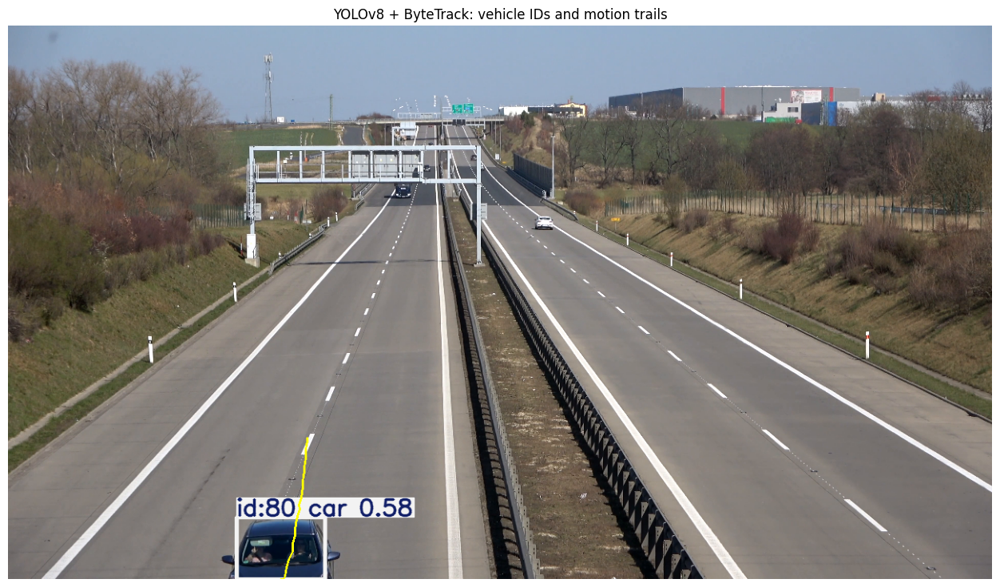

In [23]:
assert last_preview is not None, "No video frames were processed."

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(last_preview, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8 + ByteTrack: vehicle IDs and motion trails")
plt.axis("off")
plt.show()

In [24]:
import shutil
import subprocess
from IPython.display import Video, display, FileLink

PLAYABLE_PATH = WORK_DIR / "tracking_preview_h264.mp4"

if shutil.which("ffmpeg"):
    conversion = subprocess.run(
        [
            "ffmpeg", "-y",
            "-i", str(TRACK_VIDEO_PATH),
            "-an",
            "-c:v", "libx264",
            "-preset", "fast",
            "-crf", "23",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            str(PLAYABLE_PATH),
        ],
        capture_output=True,
        text=True,
    )

    if conversion.returncode == 0:
        display(Video(str(PLAYABLE_PATH), embed=True, width=900))
    else:
        print(conversion.stderr[-2000:])
        display(FileLink(str(TRACK_VIDEO_PATH)))
else:
    print("FFmpeg is unavailable. Download the preview to watch it.")
    display(FileLink(str(TRACK_VIDEO_PATH)))

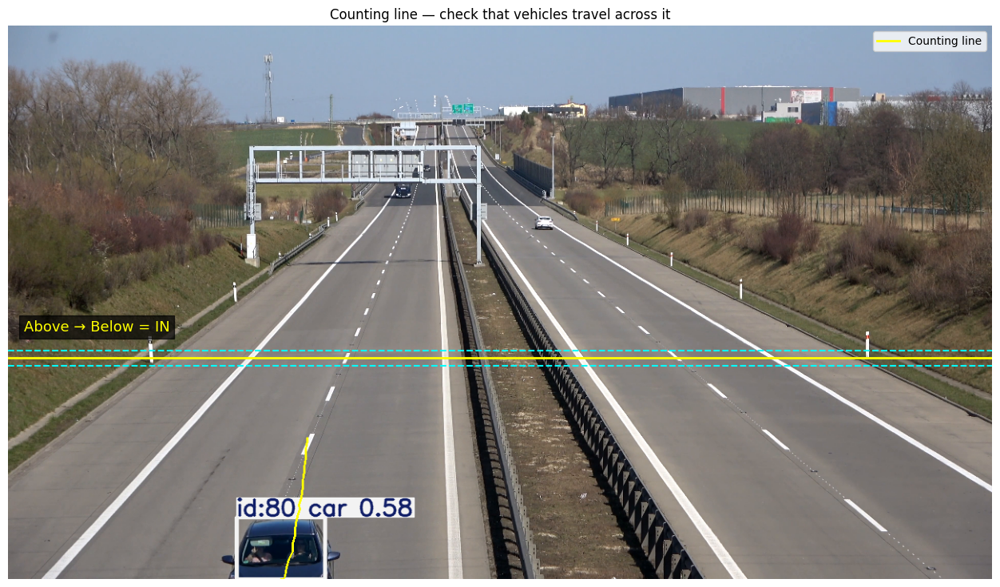

In [49]:
# Change this between 0 and 1 to move the line vertically.
LINE_POSITION = 0.60

LINE_Y = int(height * LINE_POSITION)
BAND_PIXELS = 10

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(last_preview, cv2.COLOR_BGR2RGB))

plt.axhline(LINE_Y, color="yellow", linewidth=2, label="Counting line")
plt.axhline(LINE_Y - BAND_PIXELS, color="cyan", linestyle="--")
plt.axhline(LINE_Y + BAND_PIXELS, color="cyan", linestyle="--")

plt.text(
    20, max(25, LINE_Y - 35),
    "Above → Below = IN",
    color="yellow", fontsize=13,
    bbox=dict(facecolor="black", alpha=0.7),
)

plt.title("Counting line — check that vehicles travel across it")
plt.legend()
plt.axis("off")
plt.show()

In [51]:
import pandas as pd

tracking_df = pd.read_csv(TRACK_CSV_PATH)
tracking_df = tracking_df.sort_values(["frame", "track_id"])
tracking_df = tracking_df.rename(columns={"class": "class_name"})

# Remember each track's most recent position outside the line's band.
track_states = {}
events = []

# Avoid inferring a crossing across a long observation gap.
MAX_GAP_FRAMES = max(1, round(source_fps))

for row in tracking_df.itertuples(index=False):
    track_id = int(row.track_id)
    frame_idx = int(row.frame)

    # Use bottom-center of each bounding box.
    point_y = float(row.y2)

    if point_y < LINE_Y - BAND_PIXELS:
        current_side = -1  # above
    elif point_y > LINE_Y + BAND_PIXELS:
        current_side = 1   # below
    else:
        # Inside the band: wait for a stable position outside it.
        continue

    previous = track_states.get(track_id)

    if previous is not None:
        previous_side, previous_frame = previous
        gap = frame_idx - previous_frame

        if current_side != previous_side and gap <= MAX_GAP_FRAMES:
            direction = "in" if current_side == 1 else "out"

            events.append({
                "frame": frame_idx,
                "time_seconds": round(frame_idx / source_fps, 3),
                "track_id": track_id,
                "class": row.class_name,
                "direction": direction,
            })

    track_states[track_id] = (current_side, frame_idx)

EVENTS_PATH = WORK_DIR / "crossing_events.csv"

events_df = pd.DataFrame(
    events,
    columns=["frame", "time_seconds", "track_id", "class", "direction"],
)
events_df.to_csv(EVENTS_PATH, index=False)

in_count = int((events_df["direction"] == "in").sum())
out_count = int((events_df["direction"] == "out").sum())

print("IN:", in_count)
print("OUT:", out_count)
print("NET:", in_count - out_count)
print("Events saved:", EVENTS_PATH)

display(events_df)

IN: 6
OUT: 3
NET: 3
Events saved: /kaggle/working/yolo_tracking/crossing_events.csv


,frame,time_seconds,track_id,class,direction
0,10,0.40,3,car,in
1,20,0.80,1,car,out
2,21,0.84,4,car,in
3,83,3.32,26,car,out
4,211,8.44,34,car,in
5,348,13.92,58,car,in
6,415,16.60,49,truck,in
7,422,16.88,77,car,out
8,482,19.28,80,car,in


In [15]:
COUNT_VIDEO_PATH = WORK_DIR / "counting_preview.mp4"

events_by_frame = {}
for event in events:
    events_by_frame.setdefault(event["frame"], []).append(event)

cap = cv2.VideoCapture(str(TRACK_VIDEO_PATH))
assert cap.isOpened(), "Could not open the tracking preview."

writer = cv2.VideoWriter(
    str(COUNT_VIDEO_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    source_fps,
    (width, height),
)
assert writer.isOpened(), "Could not create the counting video."

running_in = 0
running_out = 0
frame_idx = 0

try:
    while True:
        success, frame = cap.read()
        if not success:
            break

        for event in events_by_frame.get(frame_idx, []):
            if event["direction"] == "in":
                running_in += 1
            else:
                running_out += 1

        cv2.line(
            frame, (0, LINE_Y), (width - 1, LINE_Y),
            (0, 255, 255), 3,
        )

        cv2.rectangle(frame, (0, 0), (430, 115), (0, 0, 0), -1)

        labels = [
            f"IN: {running_in}   OUT: {running_out}",
            f"NET: {running_in - running_out}",
            "IN = downward | OUT = upward",
        ]

        for index, label in enumerate(labels):
            cv2.putText(
                frame, label, (15, 30 + index * 32),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                (255, 255, 255), 2,
            )

        writer.write(frame)
        frame_idx += 1

finally:
    cap.release()
    writer.release()

print("Counting video saved:", COUNT_VIDEO_PATH)

Counting video saved: /kaggle/working/yolo_tracking/counting_preview.mp4


In [52]:
COUNT_PLAYABLE_PATH = WORK_DIR / "counting_preview_h264.mp4"

if shutil.which("ffmpeg"):
    conversion = subprocess.run(
        [
            "ffmpeg", "-y",
            "-i", str(COUNT_VIDEO_PATH),
            "-an",
            "-c:v", "libx264",
            "-preset", "fast",
            "-crf", "23",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            str(COUNT_PLAYABLE_PATH),
        ],
        capture_output=True,
        text=True,
    )

    if conversion.returncode == 0:
        display(Video(str(COUNT_PLAYABLE_PATH), embed=True, width=900))
    else:
        print(conversion.stderr[-2000:])
        display(FileLink(str(COUNT_VIDEO_PATH)))
else:
    display(FileLink(str(COUNT_VIDEO_PATH)))

In [31]:
# Replace these with your manually observed counts.
MANUAL_IN = 3
MANUAL_OUT = 2

assert MANUAL_IN is not None and MANUAL_OUT is not None, (
    "Enter your manual IN and OUT counts above, then rerun."
)
assert MANUAL_IN >= 0 and MANUAL_OUT >= 0

predicted_in = int((events_df["direction"] == "in").sum())
predicted_out = int((events_df["direction"] == "out").sum())

comparison = pd.DataFrame({
    "direction": ["IN", "OUT"],
    "manual_count": [MANUAL_IN, MANUAL_OUT],
    "predicted_count": [predicted_in, predicted_out],
})

comparison["absolute_error"] = (
    comparison["predicted_count"] - comparison["manual_count"]
).abs()

display(comparison)

print(
    "Total directional count error:",
    int(comparison["absolute_error"].sum())
)

comparison.to_csv(
    WORK_DIR / "preview_count_comparison.csv",
    index=False,
)

,direction,manual_count,predicted_count,absolute_error
0,IN,3,6,3
1,OUT,2,3,1


Total directional count error: 4


In [33]:
# Inspect the rear car shown in your screenshot.
CHECK_ID = 4

debug = pd.read_csv(TRACK_CSV_PATH)
debug = debug[debug["track_id"] == CHECK_ID].copy()

debug["bottom_y"] = debug["y2"]

debug["position"] = debug["bottom_y"].apply(
    lambda y: (
        "above" if y < LINE_Y - BAND_PIXELS
        else "below" if y > LINE_Y + BAND_PIXELS
        else "inside band"
    )
)

print("Counting line Y:", LINE_Y)
print("Must move below Y =", LINE_Y + BAND_PIXELS, "to confirm IN")

# Display changes between above / band / below.
changes = debug[
    debug["position"].ne(debug["position"].shift())
]

display(changes[
    ["frame", "time_seconds", "track_id", "bottom_y", "position"]
])

print("Crossing events recorded for this ID:")
display(events_df[events_df["track_id"] == CHECK_ID])

Counting line Y: 432
Must move below Y = 442 to confirm IN


,frame,time_seconds,track_id,bottom_y,position
3,0,0.00,4,365.02,above
79,18,0.72,4,424.87,inside band
91,21,0.84,4,444.51,below


Crossing events recorded for this ID:


,frame,time_seconds,track_id,class,direction
2,21,0.84,4,car,in


In [34]:
display(
    events_df.sort_values("frame")[
        ["frame", "time_seconds", "track_id", "class", "direction"]
    ]
)

,frame,time_seconds,track_id,class,direction
0,10,0.40,3,car,in
1,20,0.80,1,car,out
2,21,0.84,4,car,in
3,83,3.32,26,car,out
4,211,8.44,34,car,in
5,348,13.92,58,car,in
6,415,16.60,49,truck,in
7,422,16.88,77,car,out
8,482,19.28,80,car,in


In [35]:
debug = pd.read_csv(TRACK_CSV_PATH)
debug = debug[debug["track_id"] == 2].copy()

debug["position"] = debug["y2"].apply(
    lambda y: (
        "above" if y < LINE_Y - BAND_PIXELS
        else "below" if y > LINE_Y + BAND_PIXELS
        else "inside band"
    )
)

changes = debug[
    debug["position"].ne(debug["position"].shift())
]

display(changes[
    ["frame", "time_seconds", "track_id", "class", "y2", "position"]
])

,frame,time_seconds,track_id,class,y2,position
1,0,0.00,2,truck,435.68,inside band
17,4,0.16,2,bus,444.25,below


In [36]:
import time
import json

benchmark_model = YOLO("yolov8n.pt")

cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), "Could not open the video."

WARMUP_FRAMES = 20
MEASURE_FRAMES = 200

measured_frames = 0
start_time = None

try:
    for index in range(WARMUP_FRAMES + MEASURE_FRAMES):
        # Start timing after the warm-up frames.
        if index == WARMUP_FRAMES:
            torch.cuda.synchronize()
            start_time = time.perf_counter()

        success, frame = cap.read()
        if not success:
            break

        frame = cv2.resize(frame, (width, height))

        tracking_result = benchmark_model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            classes=[2, 3, 5, 7],
            conf=0.1,
            imgsz=640,
            device=0,
            verbose=False,
        )[0]

        # Include transferring tracking results to CPU.
        if tracking_result.boxes is not None:
            _ = tracking_result.boxes.data.cpu().numpy()

        if index >= WARMUP_FRAMES:
            measured_frames += 1

    torch.cuda.synchronize()
    end_time = time.perf_counter()

finally:
    cap.release()

assert start_time is not None and measured_frames > 0, (
    "Video is too short for this warm-up. Reduce WARMUP_FRAMES."
)

elapsed = end_time - start_time
processing_fps = measured_frames / elapsed

benchmark = {
    "model": "yolov8n.pt",
    "tracker": "bytetrack.yaml",
    "gpu": torch.cuda.get_device_name(0),
    "ultralytics_version": ultralytics.__version__,
    "torch_version": torch.__version__,
    "input_frame_size": [width, height],
    "imgsz": 640,
    "confidence": 0.1,
    "warmup_frames": WARMUP_FRAMES,
    "measured_frames": measured_frames,
    "elapsed_seconds": round(elapsed, 3),
    "processing_fps": round(processing_fps, 2),
    "scope": "video decoding + resize + detection + tracking + CPU results",
    "excluded": "annotation, display, video encoding, model loading, warm-up",
}

print(json.dumps(benchmark, indent=2))

with open(WORK_DIR / "benchmark.json", "w") as file:
    json.dump(benchmark, file, indent=2)

print("\nSaved:", WORK_DIR / "benchmark.json")

{
  "model": "yolov8n.pt",
  "tracker": "bytetrack.yaml",
  "gpu": "Tesla T4",
  "ultralytics_version": "8.4.183",
  "torch_version": "2.11.0+cu128",
  "input_frame_size": [
    1280,
    720
  ],
  "imgsz": 640,
  "confidence": 0.1,
  "warmup_frames": 20,
  "measured_frames": 200,
  "elapsed_seconds": 5.904,
  "processing_fps": 33.87,
  "scope": "video decoding + resize + detection + tracking + CPU results",
  "excluded": "annotation, display, video encoding, model loading, warm-up"
}

Saved: /kaggle/working/yolo_tracking/benchmark.json


In [41]:
def inspect_video(path):
    capture = cv2.VideoCapture(str(path))
    assert capture.isOpened(), f"Cannot open: {path}"

    frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = capture.get(cv2.CAP_PROP_FPS)
    capture.release()

    return {
        "file": str(path),
        "frames": frames,
        "duration_seconds": round(frames / fps, 2) if fps > 0 else None,
    }

display(pd.DataFrame([
    inspect_video(VIDEO_PATH),
    inspect_video(COUNT_VIDEO_PATH),
]))

print("Crossings recorded across the processed video:")
display(events_df.sort_values("frame"))

,file,frames,duration_seconds
0,/kaggle/working/yolo_tracking/vehicles.mp4,538,21.52
1,/kaggle/working/yolo_tracking/counting_preview...,300,12.00


Crossings recorded across the processed video:


,frame,time_seconds,track_id,class,direction
0,10,0.40,3,car,in
1,20,0.80,1,car,out
2,21,0.84,4,car,in
3,83,3.32,26,car,out
4,211,8.44,34,car,in
5,348,13.92,58,car,in
6,415,16.60,49,truck,in
7,422,16.88,77,car,out
8,482,19.28,80,car,in


In [42]:
display(pd.DataFrame([
    inspect_video(VIDEO_PATH),
    inspect_video(TRACK_VIDEO_PATH),
    inspect_video(COUNT_VIDEO_PATH),
]))

,file,frames,duration_seconds
0,/kaggle/working/yolo_tracking/vehicles.mp4,538,21.52
1,/kaggle/working/yolo_tracking/tracking_preview...,538,21.52
2,/kaggle/working/yolo_tracking/counting_preview...,300,12.00


In [ ]:
from pathlib import Path
from collections import Counter
from uuid import uuid4
import subprocess
import shutil

import cv2
import pandas as pd
from IPython.display import Video, display

folder = Path("/kaggle/working/yolo_tracking")
tracking_path = folder / "tracking_preview.mp4"
events_path = folder / "crossing_events.csv"

# New filenames prevent confusion with previous previews.
run_id = uuid4().hex[:8]
raw_path = folder / f"full_counting_{run_id}.mp4"
playable_path = folder / f"full_counting_{run_id}_h264.mp4"

events_table = pd.read_csv(events_path)

cap = cv2.VideoCapture(str(tracking_path))
assert cap.isOpened(), f"Cannot open {tracking_path}"

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Tracking video:", total_frames, "frames")
assert total_frames == 538, (
    "The tracking file is still incomplete. "
    "Run Cell 8 with MAX_FRAMES = 538, then run this cell again."
)
assert fps > 0

# Same line position used in your experiment.
line_y = int(h * 0.60)

assert events_table.empty or (
    events_table["frame"].min() >= 0
    and events_table["frame"].max() < total_frames
), "Crossing events do not match the video."

events_at_frame = {}
for event in events_table.to_dict("records"):
    events_at_frame.setdefault(int(event["frame"]), []).append(
        event["direction"]
    )

writer = cv2.VideoWriter(
    str(raw_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (w, h),
)
assert writer.isOpened(), "Could not create the new video."

counts = Counter()
written = 0

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break

        counts.update(events_at_frame.get(written, []))

        cv2.line(
            frame, (0, line_y), (w - 1, line_y),
            (0, 255, 255), 3,
        )
        cv2.rectangle(frame, (0, 0), (530, 105), (0, 0, 0), -1)

        cv2.putText(
            frame,
            f"IN: {counts['in']}   OUT: {counts['out']}",
            (15, 35), cv2.FONT_HERSHEY_SIMPLEX,
            0.9, (255, 255, 255), 2,
        )
        cv2.putText(
            frame,
            f"{written / fps:.2f}s | IN downward, OUT upward",
            (15, 78), cv2.FONT_HERSHEY_SIMPLEX,
            0.65, (255, 255, 255), 2,
        )

        writer.write(frame)
        written += 1

finally:
    cap.release()
    writer.release()

assert written == total_frames, (
    f"Only wrote {written} of {total_frames} frames."
)

ffmpeg = shutil.which("ffmpeg")
assert ffmpeg, "FFmpeg was not found."

conversion = subprocess.run(
    [
        ffmpeg, "-y", "-i", str(raw_path),
        "-an", "-c:v", "libx264",
        "-preset", "fast", "-crf", "23",
        "-pix_fmt", "yuv420p",
        "-movflags", "+faststart",
        str(playable_path),
    ],
    capture_output=True,
    text=True,
)
assert conversion.returncode == 0, conversion.stderr[-2000:]

# Verify the actual file that will be displayed.
check = cv2.VideoCapture(str(playable_path))
saved_frames = int(check.get(cv2.CAP_PROP_FRAME_COUNT))
saved_fps = check.get(cv2.CAP_PROP_FPS)
check.release()

assert saved_frames == 538, f"Unexpected output: {saved_frames} frames"
assert saved_fps > 0

print(f"Verified NEW video: {saved_frames / saved_fps:.2f} seconds")
print(f"Final counts: IN={counts['in']}, OUT={counts['out']}")
print("File:", playable_path)

display(Video(str(playable_path), embed=True, width=900))